# 决策树算法

***

## 1. 决策树算法原理

**决策树提出的背景**
* 提出决策树算法的时代，机器学习的概念已经提出
* 学习是智能行为的重要特征
* 学习方法分为两类
    * 一类是能够自我改进的自适应系统
    * 一类是基于结构化知识的学习方法
* 决策树是对专家系统学习过程的改进
    * 不再依赖于领域专家
    * 直接从数据中自动归纳总结规则

**认识决策树**

决策树思想的来源非常朴素，程序设计中的条件分支就是if-then结构，最早的决策树就是利用这类结构分割数据的一种分类学习方法

## 2. 决策树分类原理详解

**举例讲解**
* 银行贷款数据
  
本表格数据是一个以“年龄”、“工作”、“房产”、“信贷情况”为特征，根据其判别“类别”这一目标值的数据

| ID | 年龄 | 有工作 | 有自己的房子 | 信贷情况 | 类别 |
|:---:|:------:|:--------:|:--------------:|:---------:|:------:|
| 1 | 青年 | 否 | 否 | 一般 | 否 |
| 2 | 青年 | 否 | 否 | 好 | 否 |
| 3 | 青年 | 是 | 否 | 好 | 是 |
| 4 | 青年 | 是 | 是 | 一般 | 是 |
| 5 | 青年 | 否 | 否 | 一般 | 否 |
| 6 | 中年 | 否 | 否 | 一般 | 否 |
| 7 | 中年 | 否 | 否 | 好 | 否 |
| 8 | 中年 | 是 | 是 | 好 | 是 |
| 9 | 中年 | 否 | 是 | 非常好 | 是 |
| 10 | 中年 | 否 | 是 | 非常好 | 是 |
| 11 | 老年 | 否 | 是 | 非常好 | 是 |
| 12 | 老年 | 否 | 是 | 好 | 是 |
| 13 | 老年 | 是 | 否 | 好 | 是 |
| 14 | 老年 | 是 | 否 | 非常好 | 是 |
| 15 | 老年 | 否 | 否 | 一般 | 否 |

* 二叉树图解
  
假设是二叉树的时候，决策树一般决策结果如下：
  <div align="center">
  <img src="./images/二叉树.png" width="500"/>
</div>

从上图我们不难发现，该决策树并没有把四个特征都放在其中，这就涉及到了如何判断决策树的优劣

**决策树的优劣**

* 分支条件的选择决定了树的优劣
* 简洁的树通常可以捕捉到最关键的分类条件
* 复杂的树有可能会发生过拟合
    <div align="center">
  <img src="./images/决策树优劣.png" width="500"/>
</div>


**决策树的重要概念——信息熵**
* 信息熵（Information Entropy）是信息论的核心概念。通俗地说就是“消除不确定性所需要的努力”，或者“一件事能带给你多少‘惊喜’的数学度量”。
* 可以将其理解为一种“代价”，而这种代价的差异与信息差有关，**信息和消除不确定性是相联系的**
    * 当我们得到的额外信息（球队历史比赛情况等等）越多的话，那么我们猜测的代价越小（猜测的不确定性减小）

**决策树的划分依据——信息增益**

* 信息增益：知道了某个条件（特征）后，事件的不确定性下降的程度
  
从上面的贷款案例来看，当我们利用某些特征后（例如是否有房子），我们能够减少不确定性。能减少的不确定性越大，就说明这个特征越重要，那如何去衡量减少的不确定性的大小呢？

**决策树的API**
* sklearn.tree.DeciisionTreeClassifier(critertion='gini', max_depth=None, random_state=None)
    * criterion: 以什么标准对树进行划分，默认是'gini'系数，也可以选择信息增益的熵'entropy'
    * max_depth: 树的深度大小（需要：关键、干净，不能过拟合）
    * random_state: 随机种子


## 3. 基于决策树进行银行贷款分类（全流程演示）

**第一步：导入工具包**

In [1]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import LabelEncoder   # 编码器
import matplotlib.pyplot as plt

**第二步：数据处理**

In [2]:
# 1. 创建数据
data = {
    'ID': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15],
    '年龄': ['青年', '青年', '青年', '青年', '青年', '中年', '中年', '中年', '中年', '中年', '老年', '老年', '老年', '老年', '老年'],
    '有工作': ['否', '否', '是', '是', '否', '否', '否', '是', '否', '否', '否', '否', '是', '是', '否'],
    '有自己的房子': ['否', '否', '否', '是', '否', '否', '否', '是', '是', '是', '是', '是', '否', '否', '否'],
    '信贷情况': ['一般', '好', '好', '一般', '一般', '一般', '好', '好', '非常好', '非常好', '非常好', '好', '好', '非常好', '一般'],
    '类别': ['否', '否', '是', '是', '否', '否', '否', '是', '是', '是', '是', '是', '是', '是', '否']
}

df = pd.DataFrame(data)

# 2. 特征工程（将分类特征转换为数值特征 - 确保所有列使用相同的编码器）
le_age = LabelEncoder()  # 实例化编码器
le_work = LabelEncoder()
le_house = LabelEncoder()
le_credit = LabelEncoder()
le_target = LabelEncoder()

df['年龄'] = le_age.fit_transform(df['年龄'])
df['有工作'] = le_work.fit_transform(df['有工作'])
df['有自己的房子'] = le_house.fit_transform(df['有自己的房子'])
df['信贷情况'] = le_credit.fit_transform(df['信贷情况'])
df['类别'] = le_target.fit_transform(df['类别'])
display('编码后数据集为:', df)

# 3. 分离特征和目标变量
X = df.drop(['ID', '类别'], axis=1)
y = df['类别']

# 4. 划分数据集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
display('训练集特征为:', X_train)

'编码后数据集为:'

,ID,年龄,有工作,有自己的房子,信贷情况,类别
0,1,2,0,0,0,0
1,2,2,0,0,1,0
2,3,2,1,0,1,1
3,4,2,1,1,0,1
4,5,2,0,0,0,0
5,6,0,0,0,0,0
6,7,0,0,0,1,0
7,8,0,1,1,1,1
8,9,0,0,1,2,1
9,10,0,0,1,2,1


'训练集特征为:'

,年龄,有工作,有自己的房子,信贷情况
8,0,0,1,2
2,2,1,0,1
1,2,0,0,1
14,1,0,0,0
4,2,0,0,0
7,0,1,1,1
10,1,0,1,2
12,1,1,0,1
3,2,1,1,0
6,0,0,0,1


**第三步：算法创建与训练**

In [3]:
# 创建决策树分类器
dt = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)  # 算法创建

# 训练模型
dt.fit(X_train, y_train)

DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)

**第四步：模型评估**

In [4]:
# 预测测试集
y_pred = dt.predict(X_test)   # 考试
print("预测答案为：",y_pred)

# 计算准确率
accuracy = accuracy_score(y_test, y_pred)
print(f"模型准确率为：{accuracy:.2f}")

# 分类报告
print("\n分类报告：")
print(classification_report(y_test, y_pred))

预测答案为： [1 1 0 1 0]
模型准确率为：1.00

分类报告：
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         3

    accuracy                           1.00         5
   macro avg       1.00      1.00      1.00         5
weighted avg       1.00      1.00      1.00         5



**第五步：决策树**

决策树规则：

|--- 有自己的房子 <= 0.50
|   |--- 有工作 <= 0.50
|   |   |--- class: 0
|   |--- 有工作 >  0.50
|   |   |--- class: 1
|--- 有自己的房子 >  0.50
|   |--- class: 1



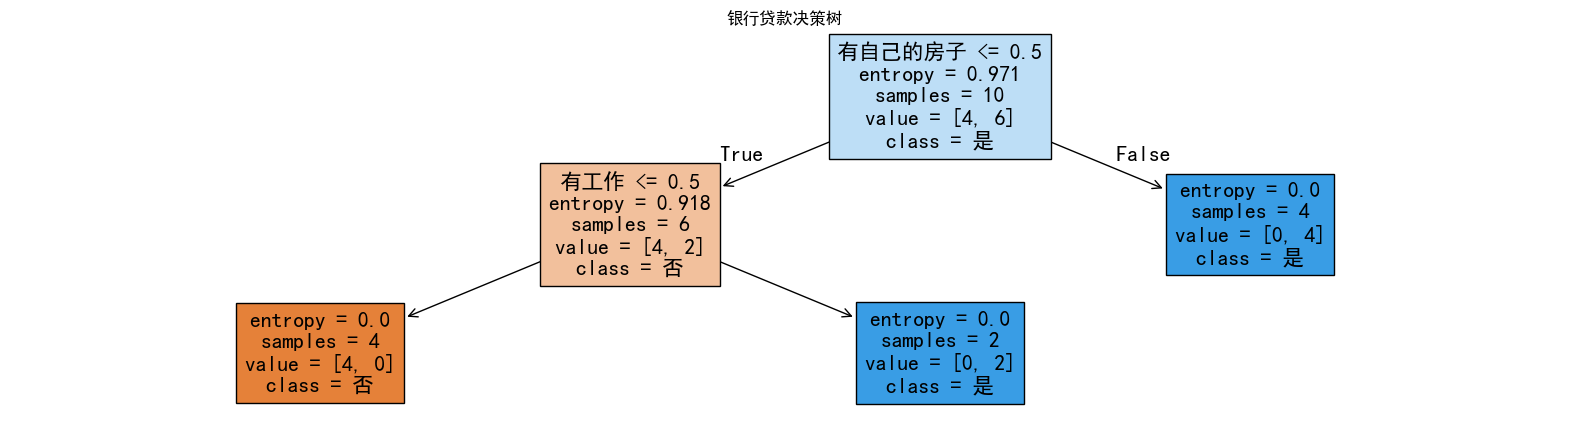

In [5]:
# 形式一：文本形式显示决策树
plt.rcParams ['font.sans-serif'] = ['SimHei']  # 用来正常显示中文标签
tree_rules = export_text(dt, feature_names=list(X.columns))  # 专门用来画文本形式决策树的函数
print("决策树规则：\n")
print(tree_rules)

# 形式二：图形化显示决策树
plt.figure(figsize=(20,5))
plot_tree(dt,feature_names=list(X.columns), class_names=['否', '是'],filled=True)
plt.title("银行贷款决策树")
plt.show()

**第六步：预测（示例）**

In [6]:
# 示例预测 - 确保使用训练时相同的编码器
sample = pd.DataFrame({
    '年龄': [le_age.transform(['中年'])[0]],  # 使用训练时的编码器
    '有工作': [le_work.transform(['是'])[0]],
    '有自己的房子': [le_house.transform(['否'])[0]],
    '信贷情况': [le_credit.transform(['一般'])[0]]
})
 
prediction = dt.predict(sample)
print(f"\n预测结果: {'批准' if prediction[0] == 1 else '不批准'}")


预测结果: 批准
